# Задача 8

Решить жёсткую систему уравнений

$$
    \begin{cases}
        u'=998\,u+1998\,v,\\
        v'=-999\,u-1999\,v.
    \end{cases}
$$

Варианты схем (явная, полунеявная и неявная):

$$
\begin{aligned}
    y^{n+1}&=y^n+h\cdot f\left(x^n,y^n\right),\\
    y^{n+1}&=y^n+\frac h2 f\left(x^n,y^n\right)+\frac h2 f\left(x^{n+1},y^{n+1}\right),\\
    y^{n+1}&=y^n+h\cdot f\left(x^{n+1},y^{n+1}\right).
\end{aligned}
$$

---

## Точное решение.

Запишем систему в виде $\mathbf y'=A\mathbf y$, $\mathbf y=(u,v)^T$:

$$
    A=\begin{pmatrix}998&1998\\-999&-1999\end{pmatrix},
    \qquad \operatorname{tr}A=-1001, \qquad \det A=1000.
$$

Характеристическое уравнение $\lambda^2+1001\lambda+1000=0$ даёт

$$
    \lambda_1=-1, \qquad \lambda_2=-1000, \qquad
    \mathbf e_1=\begin{pmatrix}2\\-1\end{pmatrix}, \qquad
    \mathbf e_2=\begin{pmatrix}1\\-1\end{pmatrix}.
$$

Обе моды затухают, но на масштабах, отличающихся в $1000$ раз:
это и есть **жёсткая система**. Начальные условия не заданы;
возьмём $u(0)=1$, $v(0)=0$. Тогда $\mathbf y(0)=\mathbf e_1-\mathbf e_2$ и

$$
    \boxed{u(x)=2e^{-x}-e^{-1000x}, \qquad v(x)=-e^{-x}+e^{-1000x}}.
$$

Быстрая мода исчезает уже при $x\sim0.01$, после чего решение
определяется медленной модой. Будем решать на отрезке $0<x<5$.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

A = np.array([[998.0, 1998.0],
              [-999.0, -1999.0]])
lambda_slow = -1.0
lambda_fast = -1000.0
x0 = 0.0
X = 5.0
y0 = np.array([1.0, 0.0])


def exact(x):
    x = np.asarray(x, dtype=float)
    slow = np.exp(lambda_slow * x)
    fast = np.exp(lambda_fast * x)
    return np.stack([2*slow - fast, -slow + fast], axis=-1)


for lam in (lambda_slow, lambda_fast):
    det = (A[0, 0] - lam)*(A[1, 1] - lam) - A[0, 1]*A[1, 0]
    print(f"det(A - λI) при λ = {lam:g}: {det:g}")
print("y(0) =", exact(0.0))
assert np.allclose(exact(0.0), y0)

det(A - λI) при λ = -1: 0
det(A - λI) при λ = -1000: 0
y(0) = [1. 0.]


## Три схемы для линейной системы.

При $f(x,\mathbf y)=A\mathbf y$ все три схемы записываются явно
через матрицы $2\times2$ ($I$ — единичная матрица):

$$
\begin{aligned}
    \text{явная:}&\qquad \mathbf y^{n+1}=(I+hA)\,\mathbf y^n,\\
    \text{полунеявная:}&\qquad \left(I-\frac h2A\right)\mathbf y^{n+1}
        =\left(I+\frac h2A\right)\mathbf y^n,\\
    \text{неявная:}&\qquad (I-hA)\,\mathbf y^{n+1}=\mathbf y^n.
\end{aligned}
$$

Для неявных схем на каждом шаге нужно решить линейную систему.
Как сказано в лекции, при больших шагах простые итерации не сходятся
($h\|A\|\gg1$), поэтому систему $2\times2$ решаем **прямо**, по формулам
Крамера. Явная и неявная схемы имеют первый порядок точности,
полунеявная (формула трапеций) — второй.

In [2]:
I2 = np.eye(2)


def solve_2x2(B, r):
    det = B[0, 0]*B[1, 1] - B[0, 1]*B[1, 0]
    if det == 0:
        raise ValueError("Матрица шага вырождена")
    return np.array([(r[0]*B[1, 1] - B[0, 1]*r[1]) / det,
                     (B[0, 0]*r[1] - r[0]*B[1, 0]) / det])


def step_explicit(A, y, h):
    return y + h * (A @ y)


def step_semi_implicit(A, y, h):
    return solve_2x2(I2 - h/2*A, y + h/2*(A @ y))


def step_implicit(A, y, h):
    return solve_2x2(I2 - h*A, y)


def solve_system(A, x0, X, y0, N, step):
    if not isinstance(N, (int, np.integer)) or N < 1:
        raise ValueError("N должно быть положительным целым числом")
    x = np.linspace(x0, X, N + 1)
    h = (X - x0) / N
    y = np.empty((N + 1, len(y0)))
    y[0] = y0
    for n in range(N):
        y[n+1] = step(A, y[n], h)
    return x, y


methods = [("Явная", step_explicit, 1),
           ("Полунеявная", step_semi_implicit, 2),
           ("Неявная", step_implicit, 1)]

## Множители усиления.

В базисе собственных векторов $\mathbf e_1,\mathbf e_2$ система распадается
на два уравнения $w'=\lambda w$, и каждая схема умножает моду на
свой множитель усиления $q(\lambda h)$:

$$
    q_{\text{явн}}=1+\lambda h, \qquad
    q_{\text{полун}}=\frac{1+\lambda h/2}{1-\lambda h/2}, \qquad
    q_{\text{неявн}}=\frac1{1-\lambda h}.
$$

Для быстрой моды $\lambda=-1000$:

* явная схема устойчива только при $|1-1000h|\le1$, то есть $h\le0.002$;
* полунеявная устойчива при любом $h$, но $q_{\text{полун}}\to-1$ при
  $h\to\infty$: быстрая мода почти не гасится и меняет знак на каждом шаге;
* неявная устойчива при любом $h$, и $q_{\text{неявн}}\to0$: быстрая мода
  подавляется, как и в точном решении.

Точный множитель за шаг равен $e^{\lambda h}$.

In [3]:
def find_factors(z):
    return {"Явная": 1 + z,
            "Полунеявная": (1 + z/2) / (1 - z/2),
            "Неявная": 1 / (1 - z)}


print("Быстрая мода, λ = -1000")
print(f"{'h':>8} {'exp(λh)':>12} " + " ".join(f"{name:>12}" for name, _, _ in methods))
for h in [0.0005, 0.001, 0.0019, 0.0021, 0.01, 0.1, 0.5]:
    q = find_factors(lambda_fast * h)
    print(f"{h:8g} {np.exp(lambda_fast*h):12.4e} "
          + " ".join(f"{q[name]:12.5f}" for name, _, _ in methods))

Быстрая мода, λ = -1000
       h      exp(λh)        Явная  Полунеявная      Неявная
  0.0005   6.0653e-01      0.50000      0.60000      0.66667
   0.001   3.6788e-01      0.00000      0.33333      0.50000
  0.0019   1.4957e-01     -0.90000      0.02564      0.34483
  0.0021   1.2246e-01     -1.10000     -0.02439      0.32258
    0.01   4.5400e-05     -9.00000     -0.66667      0.09091
     0.1   3.7201e-44    -99.00000     -0.96078      0.00990
     0.5  7.1246e-218   -499.00000     -0.99203      0.00200


## Расчёт с малым шагом.

Возьмём $h=10^{-3}$, что меньше предела устойчивости явной схемы
$0.002$ и разрешает быструю моду ($1000h=1$).

In [4]:
N = 5000
solutions = {}
for name, step, _ in methods:
    x_grid, y = solve_system(A, x0, X, y0, N, step)
    solutions[name] = y
y_exact = exact(x_grid)

print(f"N = {N}, h = {(X-x0)/N:g}")
print(f"{'x':>6} {'u точн.':>13} " + " ".join(f"{name:>13}" for name, _, _ in methods))
for i in [0, 1, 2, 5, 10, 50, 1000, N]:
    print(f"{x_grid[i]:6.3f} {y_exact[i, 0]:13.8f} "
          + " ".join(f"{solutions[name][i, 0]:13.8f}" for name, _, _ in methods))

print(f"\n{'Схема':<12} {'max |y - y_точн|':>18} {'ошибка при x=5':>16}")
for name, _, _ in methods:
    error = np.abs(solutions[name] - y_exact).max(axis=1)
    print(f"{name:<12} {error.max():18.5e} {error[-1]:16.5e}")

N = 5000, h = 0.001
     x       u точн.         Явная   Полунеявная       Неявная
 0.000    1.00000000    1.00000000    1.00000000    1.00000000
 0.001    1.63012156    1.99800000    1.66466767    1.49800200
 0.002    1.86066871    1.99600200    1.88489289    1.74600599
 0.005    1.98328701    1.99001998    1.98590973    1.95877993
 0.010    1.98005427    1.98008976    1.98008273    1.97913300
 0.050    1.90245885    1.90241126    1.90245884    1.90250638
 1.000    0.73575888    0.73539085    0.73575882    0.73612661
 5.000    0.01347589    0.01344222    0.01347589    0.01350960

Схема          max |y - y_точн|   ошибка при x=5
Явная               3.67879e-01      3.36701e-05
Полунеявная         3.45461e-02      5.61495e-09
Неявная             1.32120e-01      3.37094e-05


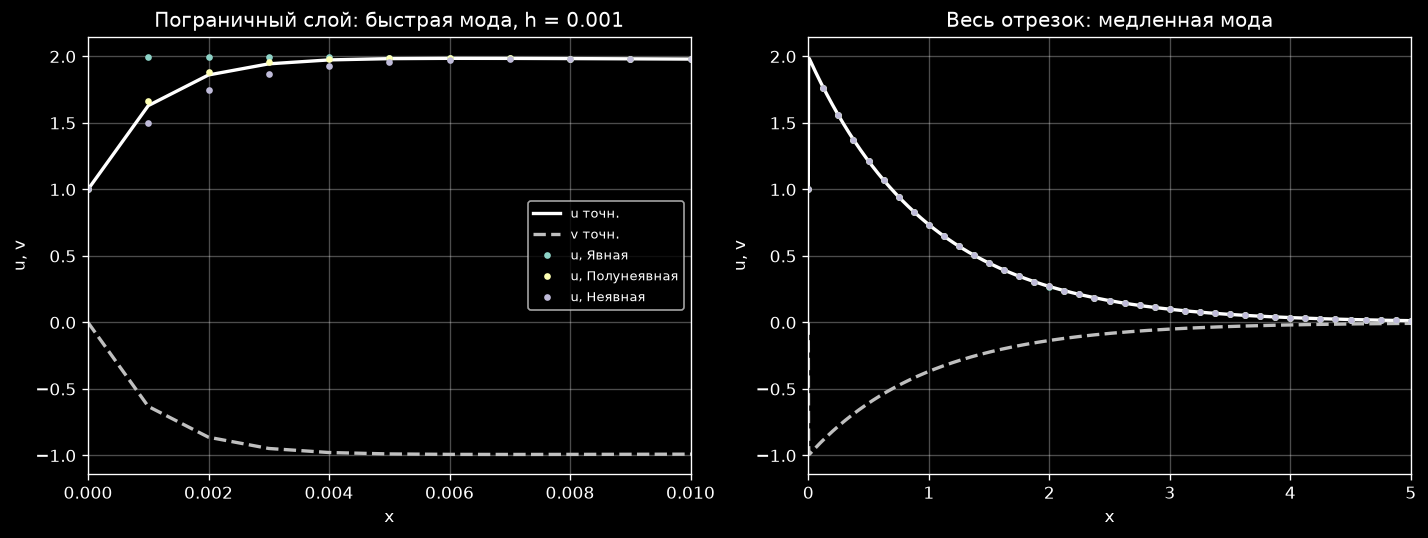

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
x_fine = np.linspace(x0, X, 5001)
for ax, x_max in zip(axes, [0.01, X]):
    ax.plot(x_fine, exact(x_fine)[:, 0], "w-", linewidth=2, label="u точн.")
    ax.plot(x_fine, exact(x_fine)[:, 1], "--", color="0.75", linewidth=2, label="v точн.")
    for name, _, _ in methods:
        mask = x_grid <= x_max
        ax.plot(x_grid[mask], solutions[name][mask, 0], "o", markersize=3,
                markevery=max(1, mask.sum() // 40), label="u, " + name)
    ax.set(xlim=(x0, x_max), xlabel="x", ylabel="u, v")
    ax.grid(True, alpha=0.3)
axes[0].set_title("Пограничный слой: быстрая мода, h = 0.001")
axes[1].set_title("Весь отрезок: медленная мода")
axes[0].legend(fontsize=8)
fig.tight_layout()
plt.show()

## Проверка порядка точности.

На сгущающихся сетках с $h\le10^{-3}$ (явная схема устойчива)
вычислим две ошибки:

$$
    E_N=\max_{0\le n\le N}\bigl\|\mathbf y^n-\mathbf y(x_n)\bigr\|_\infty,
    \qquad
    e_N=\bigl\|\mathbf y^N-\mathbf y(5)\bigr\|_\infty,
    \qquad p=\log_2\frac{E_N}{E_{2N}}.
$$

Максимум $E_N$ достигается в пограничном слое $x\lesssim0.01$, где
работает быстрая мода, а $e_N$ — ошибка медленной моды в конце отрезка.
Ожидаем $p\to1$ для явной и неявной схем и $p\to2$ для полунеявной.

In [6]:
N_values = np.array([5000, 10000, 20000, 40000])
convergence = {}
for name, step, theoretical_order in methods:
    errors, end_errors = [], []
    print("\nСхема:", name)
    print(f"{'N':>6} {'h':>10} {'E_N':>12} {'p':>7} {'e_N (x=5)':>12} {'p':>7}")
    for n in N_values:
        x, y = solve_system(A, x0, X, y0, n, step)
        error = np.max(np.abs(y - exact(x)))
        end_error = np.max(np.abs(y[-1] - exact(X)))
        if errors:
            order = np.log2(errors[-1] / error)
            end_order = np.log2(end_errors[-1] / end_error)
            orders_text = f"{order:7.3f} {end_error:12.4e} {end_order:7.3f}"
        else:
            orders_text = f"{'—':>7} {end_error:12.4e} {'—':>7}"
        print(f"{n:6d} {(X-x0)/n:10.2e} {error:12.4e} {orders_text}")
        errors.append(error)
        end_errors.append(end_error)
    convergence[name] = np.array(errors)
    assert abs(end_order - theoretical_order) < 0.01


Схема: Явная
     N          h          E_N       p    e_N (x=5)       p
  5000   1.00e-03   3.6788e-01       —   3.3670e-05       —
 10000   5.00e-04   1.1788e-01   1.642   1.6840e-05   1.000
 20000   2.50e-04   5.1473e-02   1.195   8.4212e-06   1.000
 40000   1.25e-04   2.4270e-02   1.085   4.2109e-06   1.000

Схема: Полунеявная
     N          h          E_N       p    e_N (x=5)       p
  5000   1.00e-03   3.4546e-02       —   5.6150e-09       —
 10000   5.00e-04   7.8794e-03   2.132   1.4037e-09   2.000
 20000   2.50e-04   1.9291e-03   2.030   3.5090e-10   2.000
 40000   1.25e-04   4.7982e-04   2.007   8.7824e-11   1.998

Схема: Неявная
     N          h          E_N       p    e_N (x=5)       p
  5000   1.00e-03   1.3212e-01       —   3.3709e-05       —
 10000   5.00e-04   7.6565e-02   0.787   1.6850e-05   1.000
 20000   2.50e-04   4.1720e-02   0.876   8.4237e-06   1.000
 40000   1.25e-04   2.1865e-02   0.932   4.2115e-06   1.000


В конце отрезка порядки равны теоретическим уже при $h=10^{-3}$.
Максимальная ошибка выходит на асимптотику медленнее: формула
$E_N\approx Ch^p$ справедлива, когда $|\lambda_2|h=1000h\ll1$, то есть
только когда шаг мал по сравнению с масштабом быстрой моды.
При $h=10^{-3}$ явная схема за первый шаг полностью «гасит» быструю моду
($q=1-1000h=0$), тогда как точно она убывает лишь в $e$ раз.
Это и есть проявление жёсткости: точность в пограничном слое,
как и устойчивость явной схемы, определяется быстрым масштабом.

## Большой шаг: жёсткость.

Теперь возьмём шаги больше предела устойчивости явной схемы.
Медленная мода меняется на масштабе $1$, поэтому для неё был бы
достаточен шаг порядка $0.1$. Сравним максимальную ошибку на всём отрезке
и ошибку в конце $x=5$, когда точное решение уже равно $2e^{-5}$
с точностью $e^{-5000}$.

In [7]:
print(f"{'h':>8} {'Схема':<12} {'max ошибка':>12} {'ошибка при x=5':>16}")
large = {}
for h in [0.0019, 0.0021, 0.01, 0.1, 0.5]:
    n = round((X - x0) / h)
    for name, step, _ in methods:
        with np.errstate(over="ignore", invalid="ignore"):
            x, y = solve_system(A, x0, X, y0, n, step)
            error = np.abs(y - exact(x)).max(axis=1)
        large[name, h] = (x, y)
        if np.all(np.isfinite(error)):
            print(f"{h:8g} {name:<12} {error.max():12.4e} {error[-1]:16.4e}")
        else:
            print(f"{h:8g} {name:<12} {'переполнение: решение расходится':>29}")
    print()

       h Схема          max ошибка   ошибка при x=5
  0.0019 Явная          1.0493e+00       6.3929e-05
  0.0019 Полунеявная    1.2389e-01       2.0263e-08
  0.0019 Неявная        1.9525e-01       6.4071e-05

  0.0021 Явная          3.2847e+98       3.2847e+98
  0.0021 Полунеявная    1.4684e-01       2.4761e-08
  0.0021 Неявная        2.0012e-01       7.0834e-05

    0.01 Явная        переполнение: решение расходится
    0.01 Полунеявная    6.6671e-01       5.6149e-07
    0.01 Неявная        9.0815e-02       3.3886e-04

     0.1 Явная          6.0501e+99       6.0501e+99
     0.1 Полунеявная    9.6071e-01       1.3536e-01
     0.1 Неявная        3.5328e-02       3.5612e-03

     0.5 Явная          9.5721e+26       9.5721e+26
     0.5 Полунеявная    9.9989e-01       9.2450e-01
     0.5 Неявная        1.5313e-01       2.1207e-02



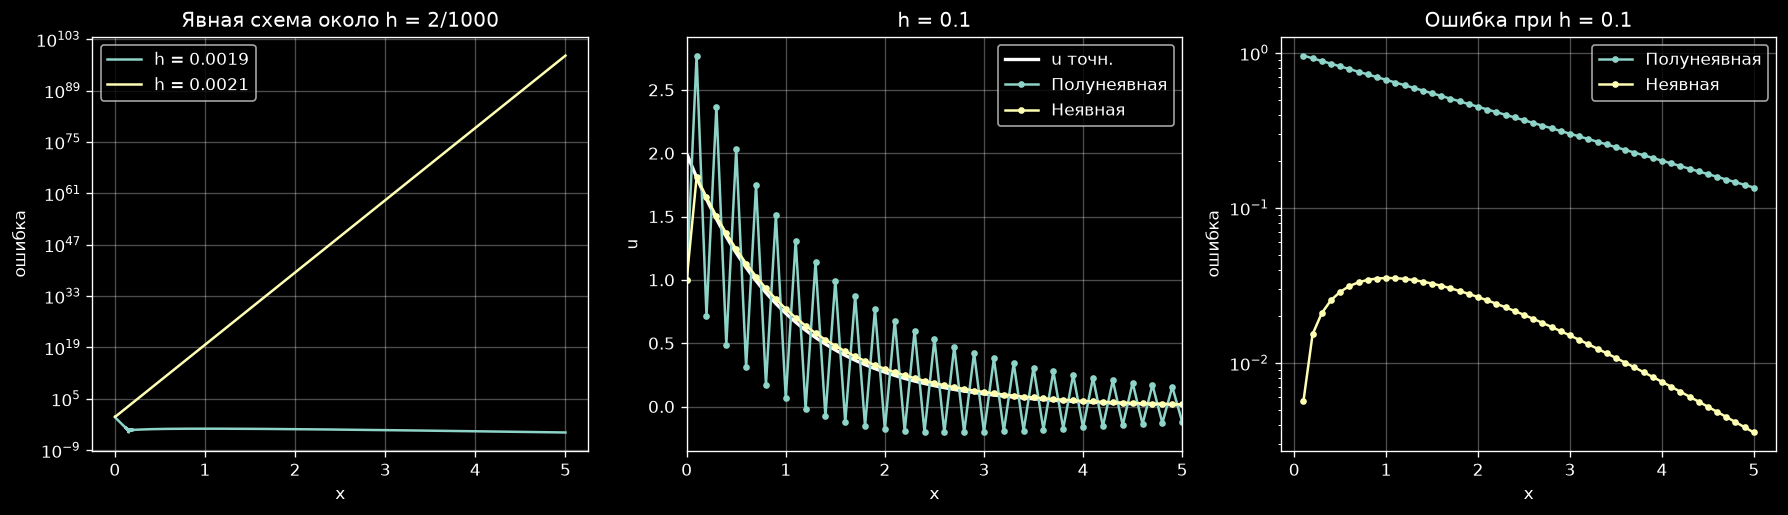

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.4))

ax = axes[0]
for h in [0.0019, 0.0021]:
    x, y = large["Явная", h]
    ax.semilogy(x[1:], np.abs(y - exact(x)).max(axis=1)[1:], label=f"h = {h:g}")
ax.set(xlabel="x", ylabel="ошибка", title="Явная схема около h = 2/1000")

ax = axes[1]
ax.plot(x_fine, exact(x_fine)[:, 0], "w-", linewidth=2, label="u точн.")
for name in ["Полунеявная", "Неявная"]:
    x, y = large[name, 0.1]
    ax.plot(x, y[:, 0], "o-", markersize=3, label=name)
ax.set(xlabel="x", ylabel="u", xlim=(x0, X), title="h = 0.1")

ax = axes[2]
for name in ["Полунеявная", "Неявная"]:
    x, y = large[name, 0.1]
    ax.semilogy(x[1:], np.abs(y - exact(x)).max(axis=1)[1:], "o-",
                markersize=3, label=name)
ax.set(xlabel="x", ylabel="ошибка", title="Ошибка при h = 0.1")

for ax in axes:
    ax.grid(True, alpha=0.3)
    ax.legend()
fig.tight_layout()
plt.show()

Явная схема при $h=0.0019$ даёт правильный результат, а при $h=0.0021$
множитель быстрой моды $|1-2.1|=1.1>1$. Быстрая мода из начальных данных
растёт как $1.1^n$, и к $x=5$ ошибка достигает $1.1^{2381}\approx3\cdot10^{98}$,
хотя в точном решении этой моды давно нет. Даже если бы её не было
в начальных данных, её затравкой стали бы ошибки округления.

Обе неявные схемы при $h=0.1$ устойчивы. Неявная схема сразу гасит
быструю моду ($q=1/101$), и дальше ошибка определяется только
медленной модой. У полунеявной схемы $q=-49/51\approx-0.96$: быстрая
мода затухает медленно и меняет знак на каждом шаге. Поэтому,
несмотря на второй порядок точности, её ошибка больше: при $x=5$
она равна остатку быстрой моды $(49/51)^{50}\approx0.135$.
При $h=0.5$ остаток $(249/251)^{10}\approx0.92$.

## Независимая проверка.

В базисе собственных векторов численное решение каждой схемы
выписывается явно:

$$
    \mathbf y^n=q(\lambda_1h)^n\,\mathbf e_1-q(\lambda_2h)^n\,\mathbf e_2.
$$

Сравним это с результатом пошагового расчёта для всех схем и шагов,
при которых схема устойчива. Это проверяет реализацию формул шага,
а не точность метода.

In [9]:
e1 = np.array([2.0, -1.0])
e2 = np.array([1.0, -1.0])
print(f"{'h':>8} {'Схема':<12} {'max |y - формула|':>20}")
for (name, h), (x, y) in large.items():
    n = np.arange(len(x))[:, None]
    h_grid = (X - x0) / (len(x) - 1)
    q_slow = find_factors(lambda_slow * h_grid)[name]
    q_fast = find_factors(lambda_fast * h_grid)[name]
    if abs(q_fast) <= 1:
        formula = q_slow**n * e1 - q_fast**n * e2
        difference = np.max(np.abs(y - formula))
        print(f"{h:8g} {name:<12} {difference:20.3e}")
        assert difference < 1e-12
    else:
        print(f"{h:8g} {name:<12} {'неустойчива, |q| > 1':>20}")
print("Формулы шага проверены.")

       h Схема           max |y - формула|
  0.0019 Явная                   2.531e-14
  0.0019 Полунеявная             9.681e-14
  0.0019 Неявная                 1.298e-13
  0.0021 Явная        неустойчива, |q| > 1
  0.0021 Полунеявная             9.326e-15
  0.0021 Неявная                 1.218e-13
    0.01 Явная        неустойчива, |q| > 1
    0.01 Полунеявная             9.448e-14
    0.01 Неявная                 1.252e-13
     0.1 Явная        неустойчива, |q| > 1
     0.1 Полунеявная             1.197e-13
     0.1 Неявная                 1.512e-13
     0.5 Явная        неустойчива, |q| > 1
     0.5 Полунеявная             2.065e-13
     0.5 Неявная                 3.331e-16
Формулы шага проверены.


## Ответ.

Точное решение при $u(0)=1$, $v(0)=0$:

$$
    \boxed{u=2e^{-x}-e^{-1000x}, \qquad v=-e^{-x}+e^{-1000x}}.
$$

Собственные числа $-1$ и $-1000$, отношение масштабов $1000$.
Схемы на $\mathbf y'=A\mathbf y$ имеют вид

$$
\boxed{
\begin{aligned}
    &\text{явная:} && \mathbf y^{n+1}=(I+hA)\mathbf y^n,
        && h\le0.002,\ p=1,\\
    &\text{полунеявная:} && \mathbf y^{n+1}
        =\left(I-\tfrac h2A\right)^{-1}\!\left(I+\tfrac h2A\right)\mathbf y^n,
        && \text{любой }h,\ p=2,\\
    &\text{неявная:} && \mathbf y^{n+1}=(I-hA)^{-1}\mathbf y^n,
        && \text{любой }h,\ p=1.
\end{aligned}}
$$

Шаг явной схемы ограничен быстрой модой, даже когда она уже затухла.
Неявные схемы позволяют выбирать шаг по медленной моде. Неявная схема
к тому же сразу гасит быструю моду, а полунеявная при большом шаге
оставляет её в виде медленно затухающих знакопеременных колебаний.